## Testing how well the models fit
Could also be used to change e.g. size of network, but now worked on a brief proof of concept to train all models (in parallel) and compare them.




In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.NeuralODE import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import TrainingJob, run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

## Data generation

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [10]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [7]
sparsity_list = [0.05]

sim_outputs = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = Path("../data/fitting_on_multiple_sim_settings") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_result = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
            )
            sim_outputs.append(sim_result) 
sim_outputs

2025-10-16 11:06:26,641 - INFO - Generating network
Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_0) + ~(Node_3)
my_network: Node_1: (Node_5*Node_0) + (Node_1)
my_network: Node_2: (Node_2)
my_network: Node_3: (Node_3) + ~(Node_0)
my_network: Node_4: ~(Node_4)
my_network: Node_5: (Node_5) + ~(Node_1)
my_network: Node_6: (Node_3) + (Node_1)
my_network: Node_7: ~(Node_7) + (Node_3)
my_network: Node_8: ~(Node_0)
my_network: Node_9: (Node_9)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/my_network.xml

Thomas Schaffter (thomas.schaff...@gmail.com)
Daniel Marbach (daniel.marb...@gmail.com)
Gilles Roulet (gilles.rou...@gmail.com)

http://tschaffter.ch/projects/gnw
2025-10-16 11:06:27,308 - INFO - Simulating network expr

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05'), network_name='my_network', nr_genes=10, nr_modules=7, sparsity=0.05, keep_self_interactions=True)]

## Model fitting

In [3]:
devices = ["cuda:0", "cuda:1"]
# hidden_sizes = [8, 16]
hidden_sizes = [2, 5, 10]

train_jobs: list[TrainingJob] = []
train_steps = 200
train_jobs.extend([
    TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)]}, optimizer_kwargs={'lr': .1})
    for i, sim_result in enumerate(sim_outputs)
])
for hidden_size in hidden_sizes:
    train_jobs.extend([
        TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
        for i, sim_result in enumerate(sim_outputs)
    ])
train_steps = 200
train_jobs.extend([
    TrainingJob(CellBox, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'self_activations': True}, optimizer_kwargs={'lr': .1})
    for i, sim_result in enumerate(sim_outputs)
])

len(train_jobs)


5

In [ ]:
train_jobs

In [ ]:
train_jobs[0].run()

In [ ]:
[i.trainer.model.device for i in train_jobs]

In [4]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=5) as pool:
    pool.map(run_training_job, train_jobs)

2025-10-16 11:06:50,742 [SpawnPoolWorker-5] Epoch 0, loss 0.09996714442968369
2025-10-16 11:06:50,854 [SpawnPoolWorker-5] Epoch 1, loss 0.07551432400941849
2025-10-16 11:06:50,973 [SpawnPoolWorker-5] Epoch 2, loss 0.05916370823979378
2025-10-16 11:06:51,036 [SpawnPoolWorker-3] Epoch 0, loss 0.06289355456829071
2025-10-16 11:06:51,097 [SpawnPoolWorker-5] Epoch 3, loss 0.04845670238137245
2025-10-16 11:06:51,237 [SpawnPoolWorker-5] Epoch 4, loss 0.0421786867082119
2025-10-16 11:06:51,411 [SpawnPoolWorker-5] Epoch 5, loss 0.039066705852746964
2025-10-16 11:06:51,581 [SpawnPoolWorker-5] Epoch 6, loss 0.03761443495750427
2025-10-16 11:06:51,753 [SpawnPoolWorker-5] Epoch 7, loss 0.03660600259900093
2025-10-16 11:06:51,929 [SpawnPoolWorker-5] Epoch 8, loss 0.03552249073982239
2025-10-16 11:06:52,093 [SpawnPoolWorker-5] Epoch 9, loss 0.034390103071928024
2025-10-16 11:06:52,251 [SpawnPoolWorker-5] Epoch 10, loss 0.0334240198135376
2025-10-16 11:06:52,252 [SpawnPoolWorker-3] Epoch 1, loss 0.116

In [ ]:
from halcyon.Trainer import ResultList


result_list = ResultList.from_train_jobs(train_jobs)

In [ ]:
# Assuming `results` is a list of dicts
df = result_list.to_dataframe()


,final_loss,nr_training_steps,model_path,model_cls,data_path,network_name,nr_genes,nr_modules,sparsity,keep_self_interactions,device,lr,hidden_size,self_activations
0,0.016296,200,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixOnlyAddLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,10,7,0.05,True,cuda:0,0.1,NaN,NaN
1,0.001939,200,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,10,7,0.05,True,cuda:0,0.1,2.0,NaN
2,0.001339,200,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,10,7,0.05,True,cuda:0,0.1,5.0,NaN
3,0.012830,200,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,10,7,0.05,True,cuda:0,0.1,10.0,NaN
4,0.015612,200,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,CellBox,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,10,7,0.05,True,cuda:0,0.1,NaN,True


In [7]:
df['model_overall_name'] = df['model_cls'].astype(str) + '_' + df['hidden_size'].astype(str)

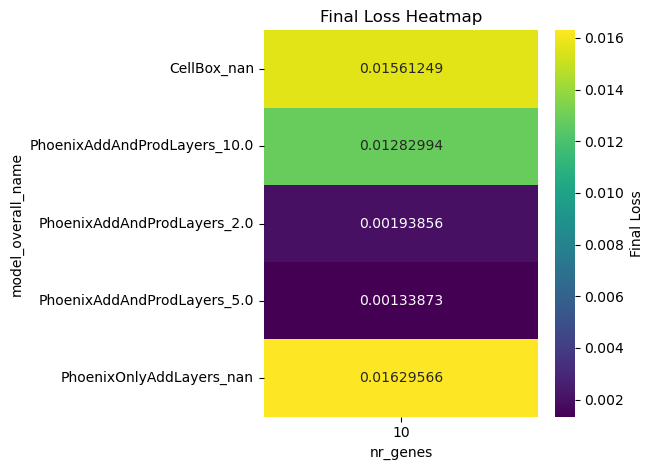

In [ ]:
# TODO at some point move this into class methods
# Pivot so genes = columns, modules = rows
heatmap_data = df.pivot_table(
    index="model_overall_name",
    columns="nr_genes",
    values="final_loss",
    # aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,        # write values in the cells
    fmt=".8f",         # number format
    cmap="viridis",    # colour map
    cbar_kws={"label": "Final Loss"}
)
# plt.xlabel("Number of Genes")
# plt.ylabel("Model")
plt.title("Final Loss Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
train_jobs

In [ ]:
train_jobs[2].summary()

In [ ]:
import torch
with torch.no_grad():
    train_jobs[3].trainer.model.decay_params[0] = 1

/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/trained_trainer_PhoenixOnlyAddLayers_lr_0.1.pt


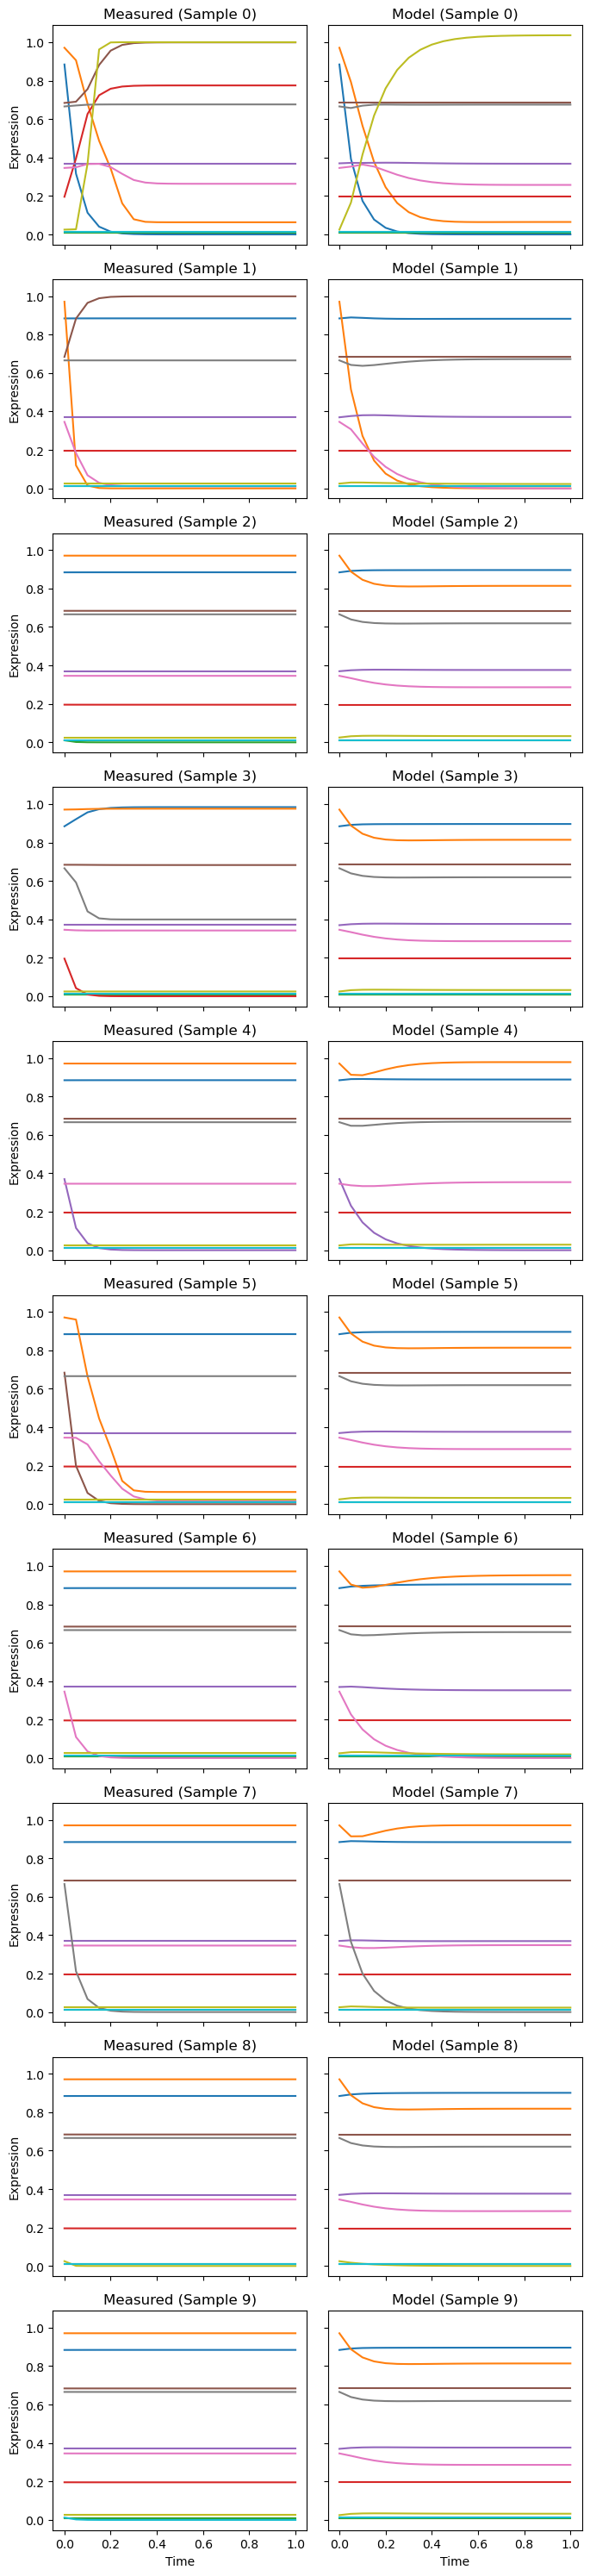

/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_2_lr_0.1.pt


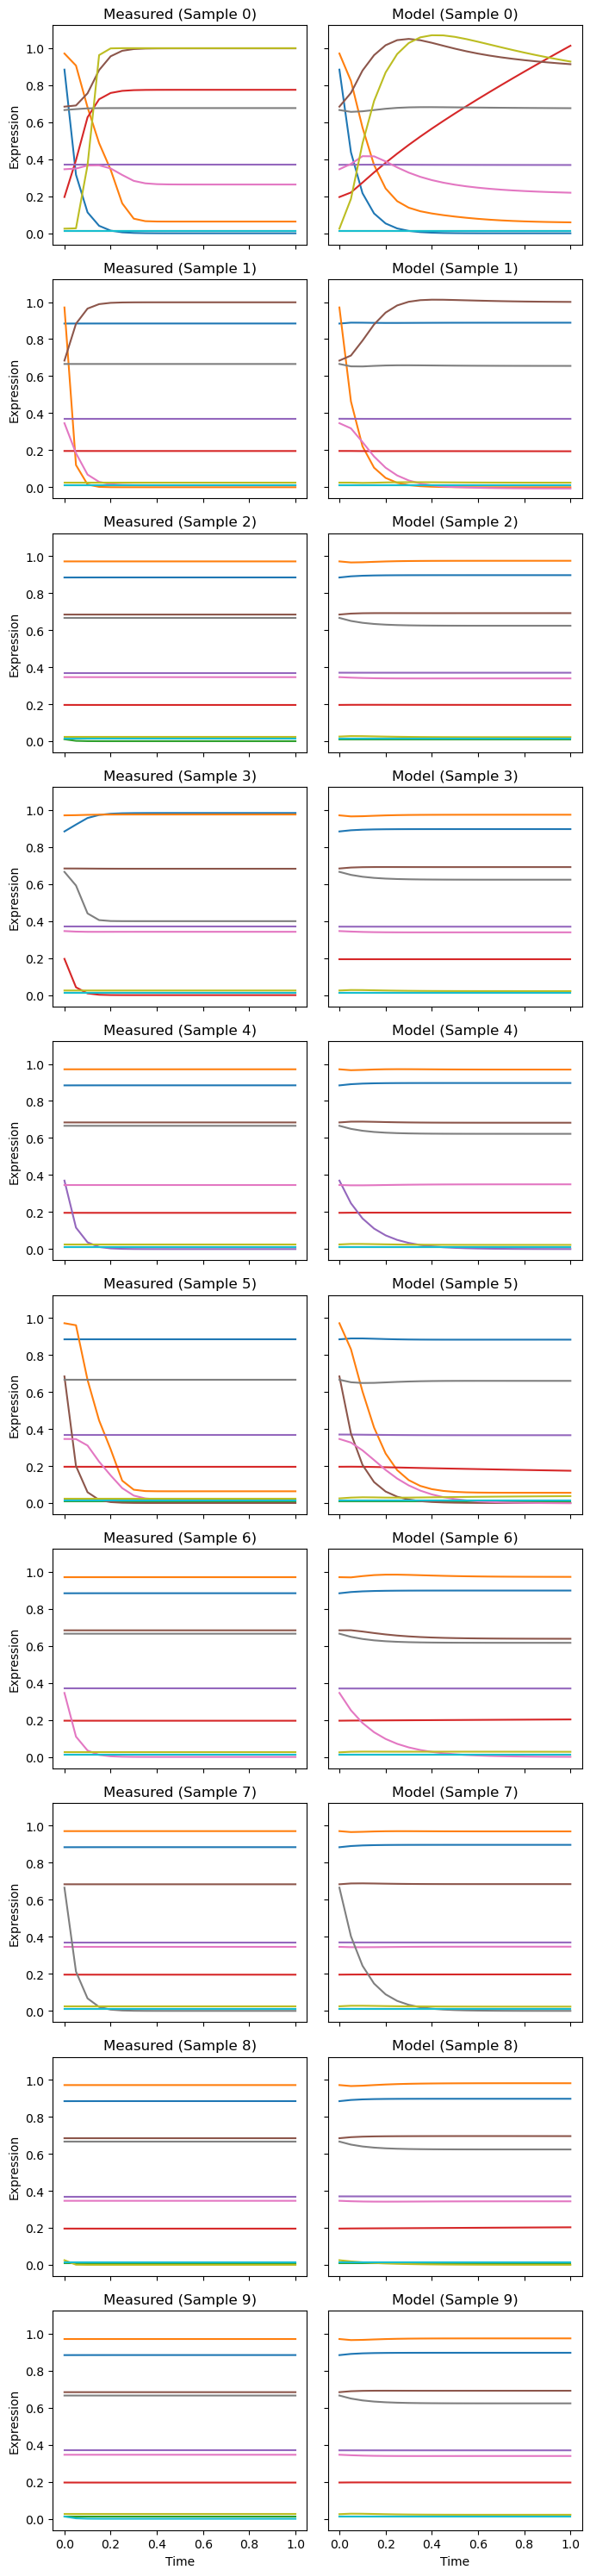

/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_5_lr_0.1.pt


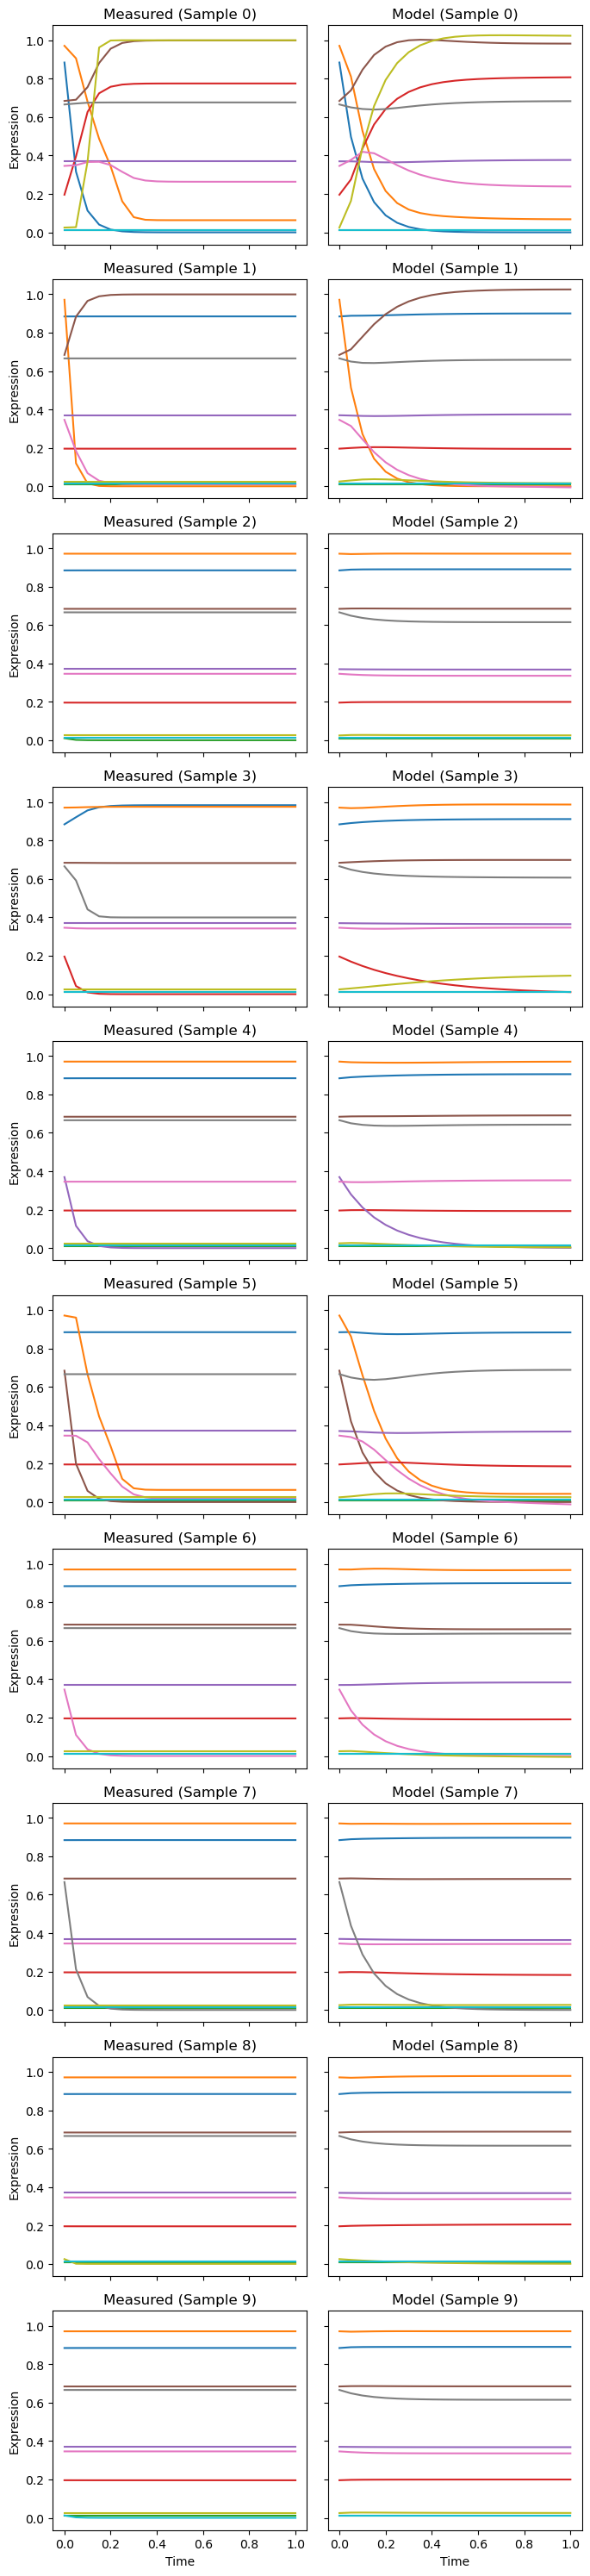

/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_10_lr_0.1.pt


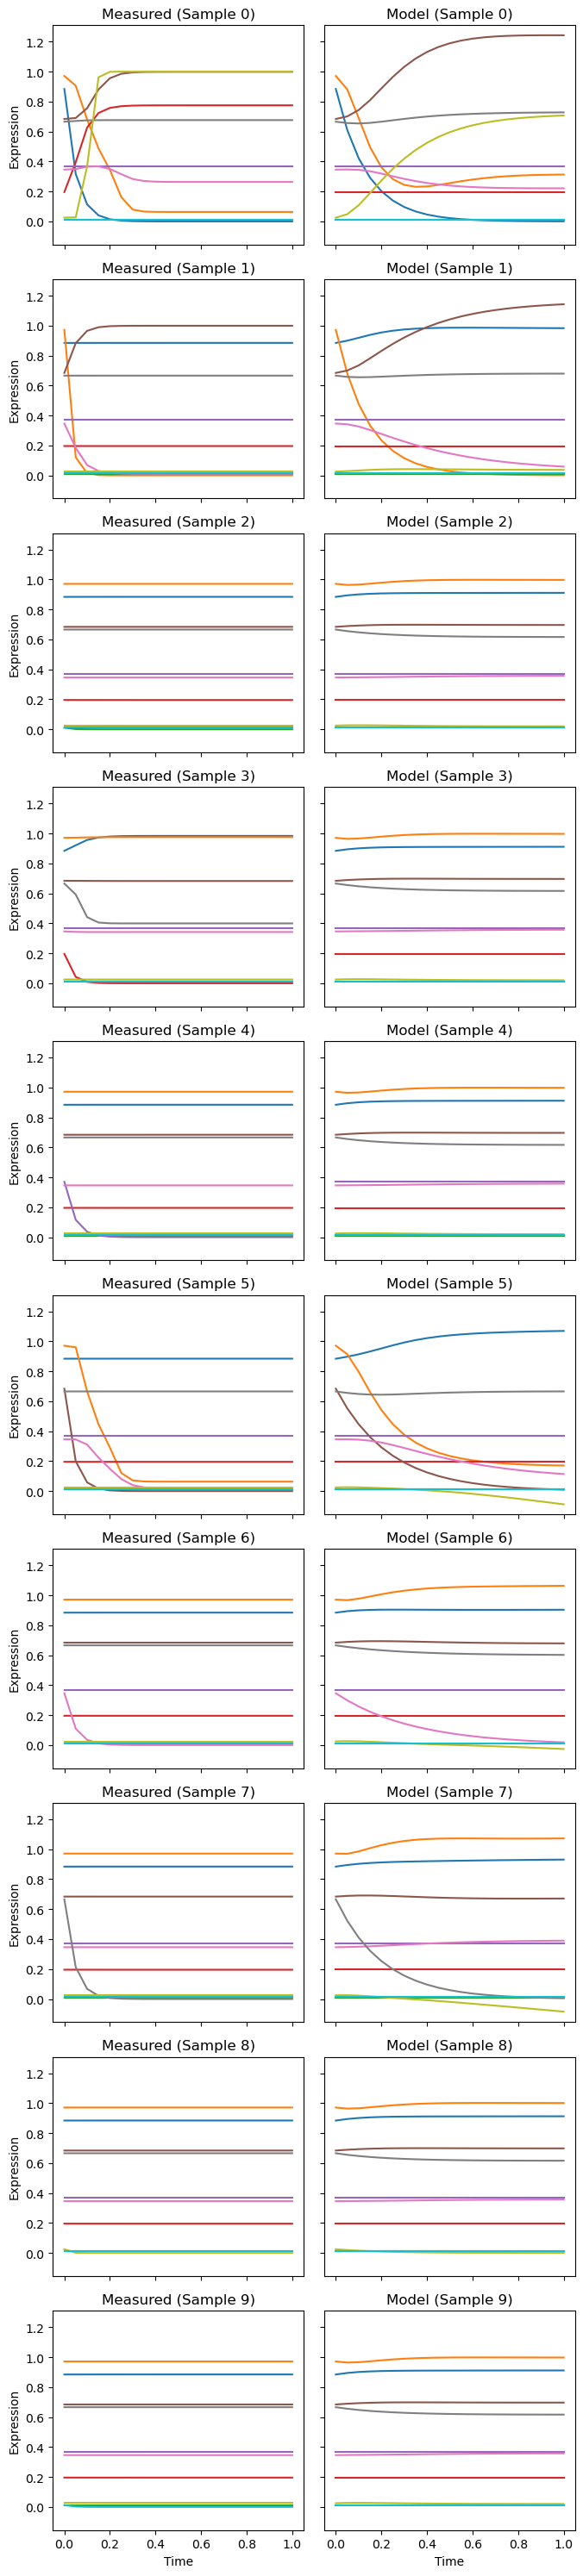

/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_10_modules_7_sparsity_0.05/trained_trainer_CellBox_self_activations_True_lr_0.1.pt


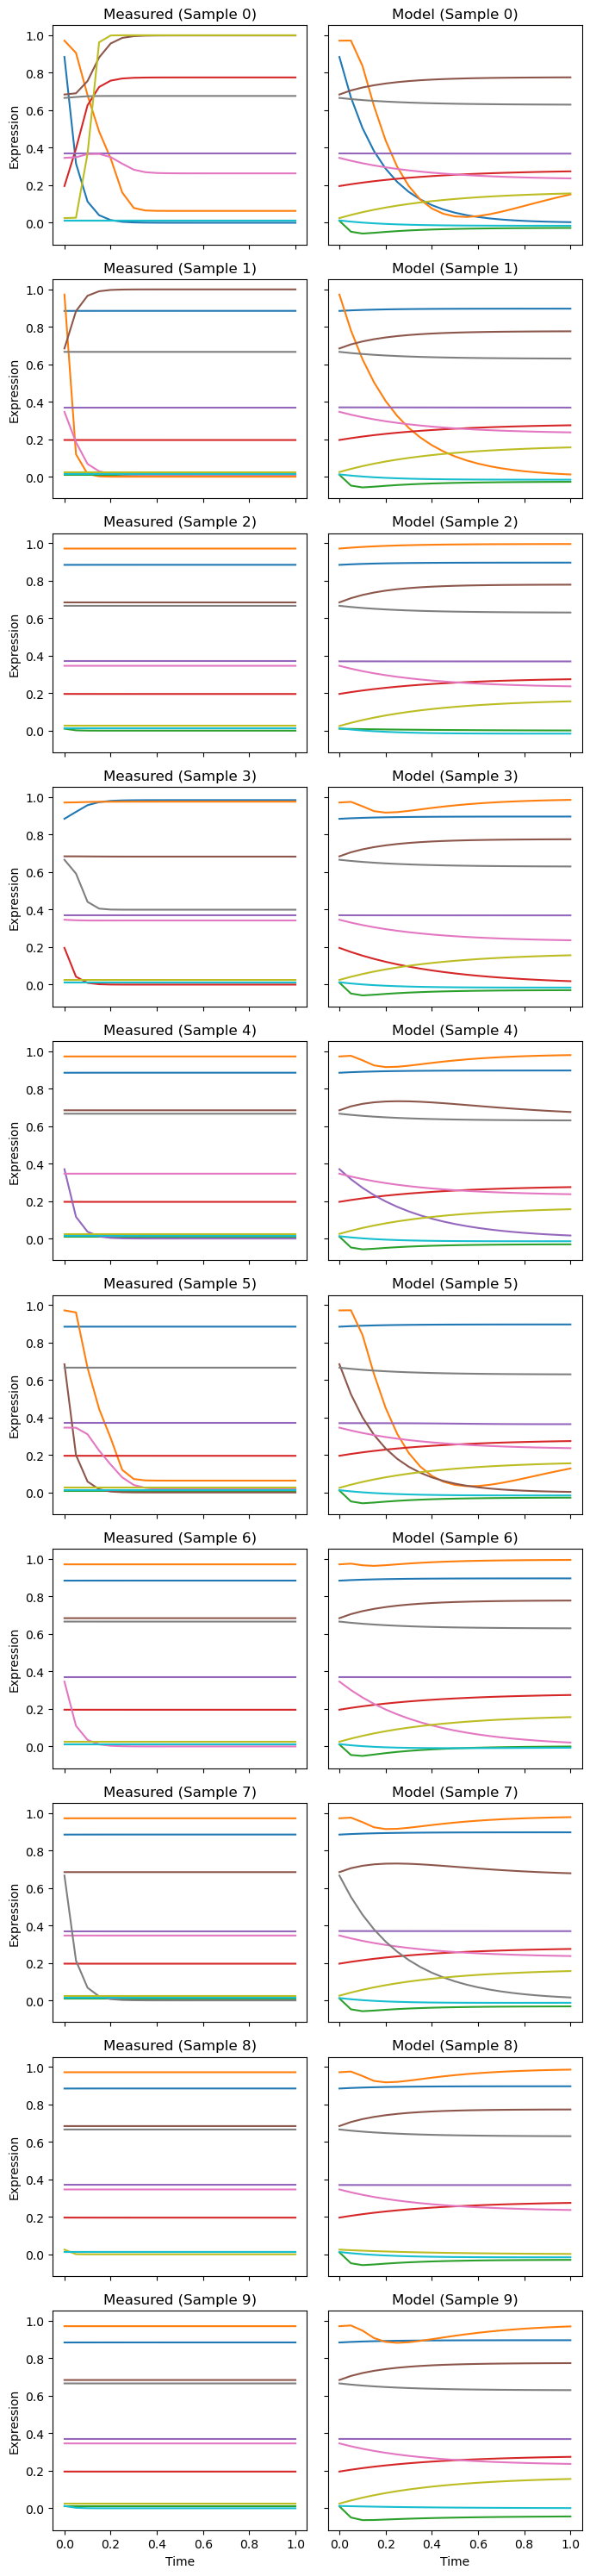

In [22]:
for train_job in train_jobs:
    print(train_job.summary()['model_path'])
    train_job.trainer.plot_fit_vs_real(show_legend=False)
    plt.show()

(<Figure size 500x2000 with 20 Axes>,
 array([[<Axes: title={'center': 'Measured (Sample 0)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 0)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 1)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 1)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 2)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 2)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 3)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 3)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 4)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model (Sample 4)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center':

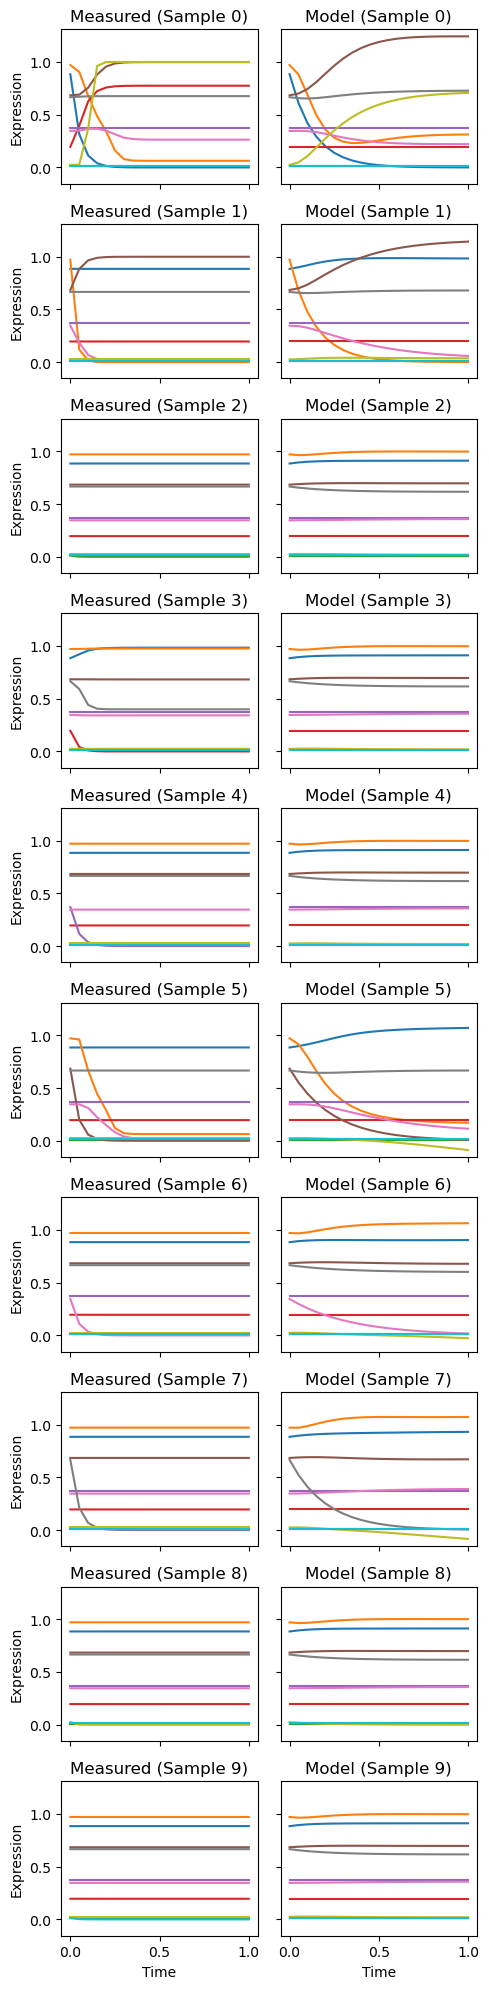